In [2]:
import torch

data = torch.load(
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/target_hidden_states.pt",
    map_location="cpu",
)

print(data.keys())

dict_keys(['image_paths', 'conditions', 'num_distractors', 'trials', 'image_width', 'image_height', 'target_x', 'target_y', 'target_x_px', 'target_y_px', 'bbox_left', 'bbox_top', 'bbox_right', 'bbox_bottom', 'raw_h', 'raw_w', 'token_h', 'token_w', 'merge_size', 'raw_patch_x', 'raw_patch_y', 'target_token_x', 'target_token_y', 'target_token_idx', 'bbox_token_indices', 'window3x3_indices', 'center_token_hidden', 'bbox_mean_hidden', 'window3x3_mean_hidden', 'bbox_hidden', 'window3x3_hidden'])


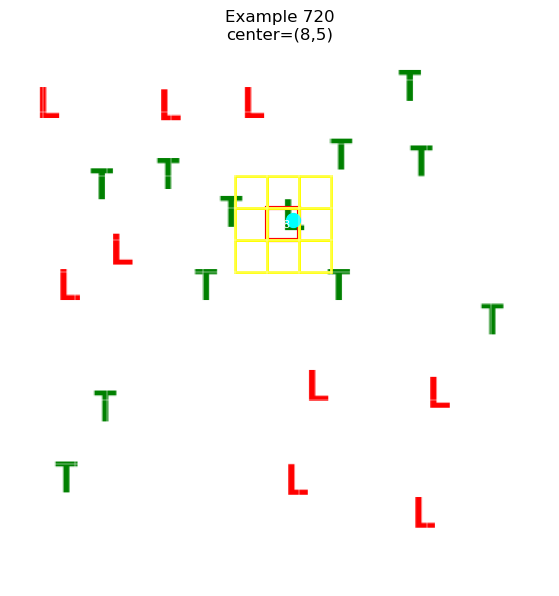

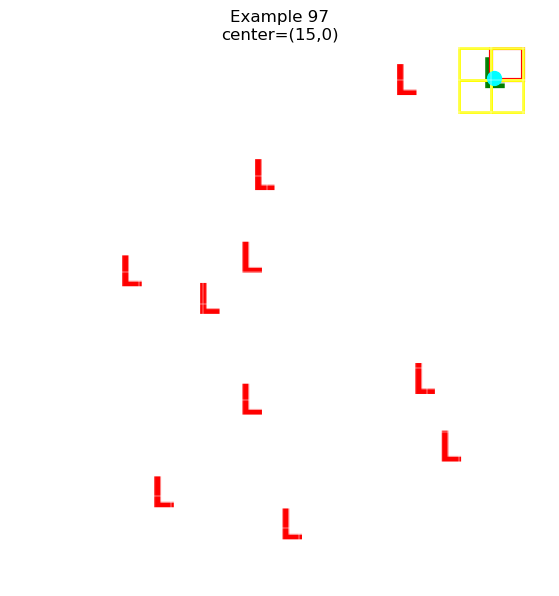

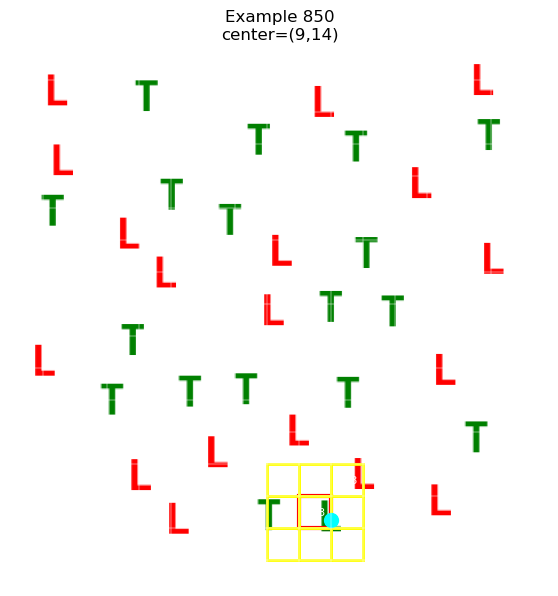

In [3]:
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import torch
import numpy as np

IMAGE_SIZE = 448
TOKEN_GRID_SIZE = 16
TOKEN_SIZE = IMAGE_SIZE / TOKEN_GRID_SIZE

# 3 random exmaples

rng = np.random.default_rng(42)

indices = rng.choice(
    len(data["image_paths"]),
    size=min(3, len(data["image_paths"])),
    replace=False,
)

for i in indices:

    path = data["image_paths"][i]

    image = Image.open(path).convert("RGB")

    fig, ax = plt.subplots(
        figsize=(7, 7)
    )

    ax.imshow(image)


    for x in range(TOKEN_GRID_SIZE + 1):
        ax.axvline(
            x * TOKEN_SIZE,
            color="white",
            alpha=0.25,
        )

    for y in range(TOKEN_GRID_SIZE + 1):
        ax.axhline(
            y * TOKEN_SIZE,
            color="white",
            alpha=0.25,
        )

    # --------------------------------------------------
    # center token
    # --------------------------------------------------

    tx = int(data["target_token_x"][i])
    ty = int(data["target_token_y"][i])

    rect = patches.Rectangle(
        (
            tx * TOKEN_SIZE,
            ty * TOKEN_SIZE,
        ),
        TOKEN_SIZE,
        TOKEN_SIZE,
        linewidth=3,
        edgecolor="red",
        facecolor="none",
    )

    ax.add_patch(rect)



    for y in range(
        max(0, ty - 1),
        min(TOKEN_GRID_SIZE, ty + 2),
    ):
        for x in range(
            max(0, tx - 1),
            min(TOKEN_GRID_SIZE, tx + 2),
        ):

            rect = patches.Rectangle(
                (
                    x * TOKEN_SIZE,
                    y * TOKEN_SIZE,
                ),
                TOKEN_SIZE,
                TOKEN_SIZE,
                linewidth=2,
                edgecolor="yellow",
                facecolor="none",
            )

            ax.add_patch(rect)

            idx = (
                y * TOKEN_GRID_SIZE
                + x
            )

            ax.text(
                x * TOKEN_SIZE
                + TOKEN_SIZE / 2,
                y * TOKEN_SIZE
                + TOKEN_SIZE / 2,
                str(idx),
                color="white",
                fontsize=8,
                ha="center",
                va="center",
            )



    if "target_x" in data:

        px = (
            (
                data["target_x"][i].item()
                - 0.5
            )
            / 9.0
            * IMAGE_SIZE
        )

        py = IMAGE_SIZE - (
            (
                data["target_y"][i].item()
                - 0.5
            )
            / 9.0
            * IMAGE_SIZE
        )

        ax.scatter(
            px,
            py,
            c="cyan",
            s=100,
            label="target center",
        )

    ax.set_title(
        f"Example {i}\n"
        f"center=({tx},{ty})"
    )

    ax.axis("off")
    plt.show()

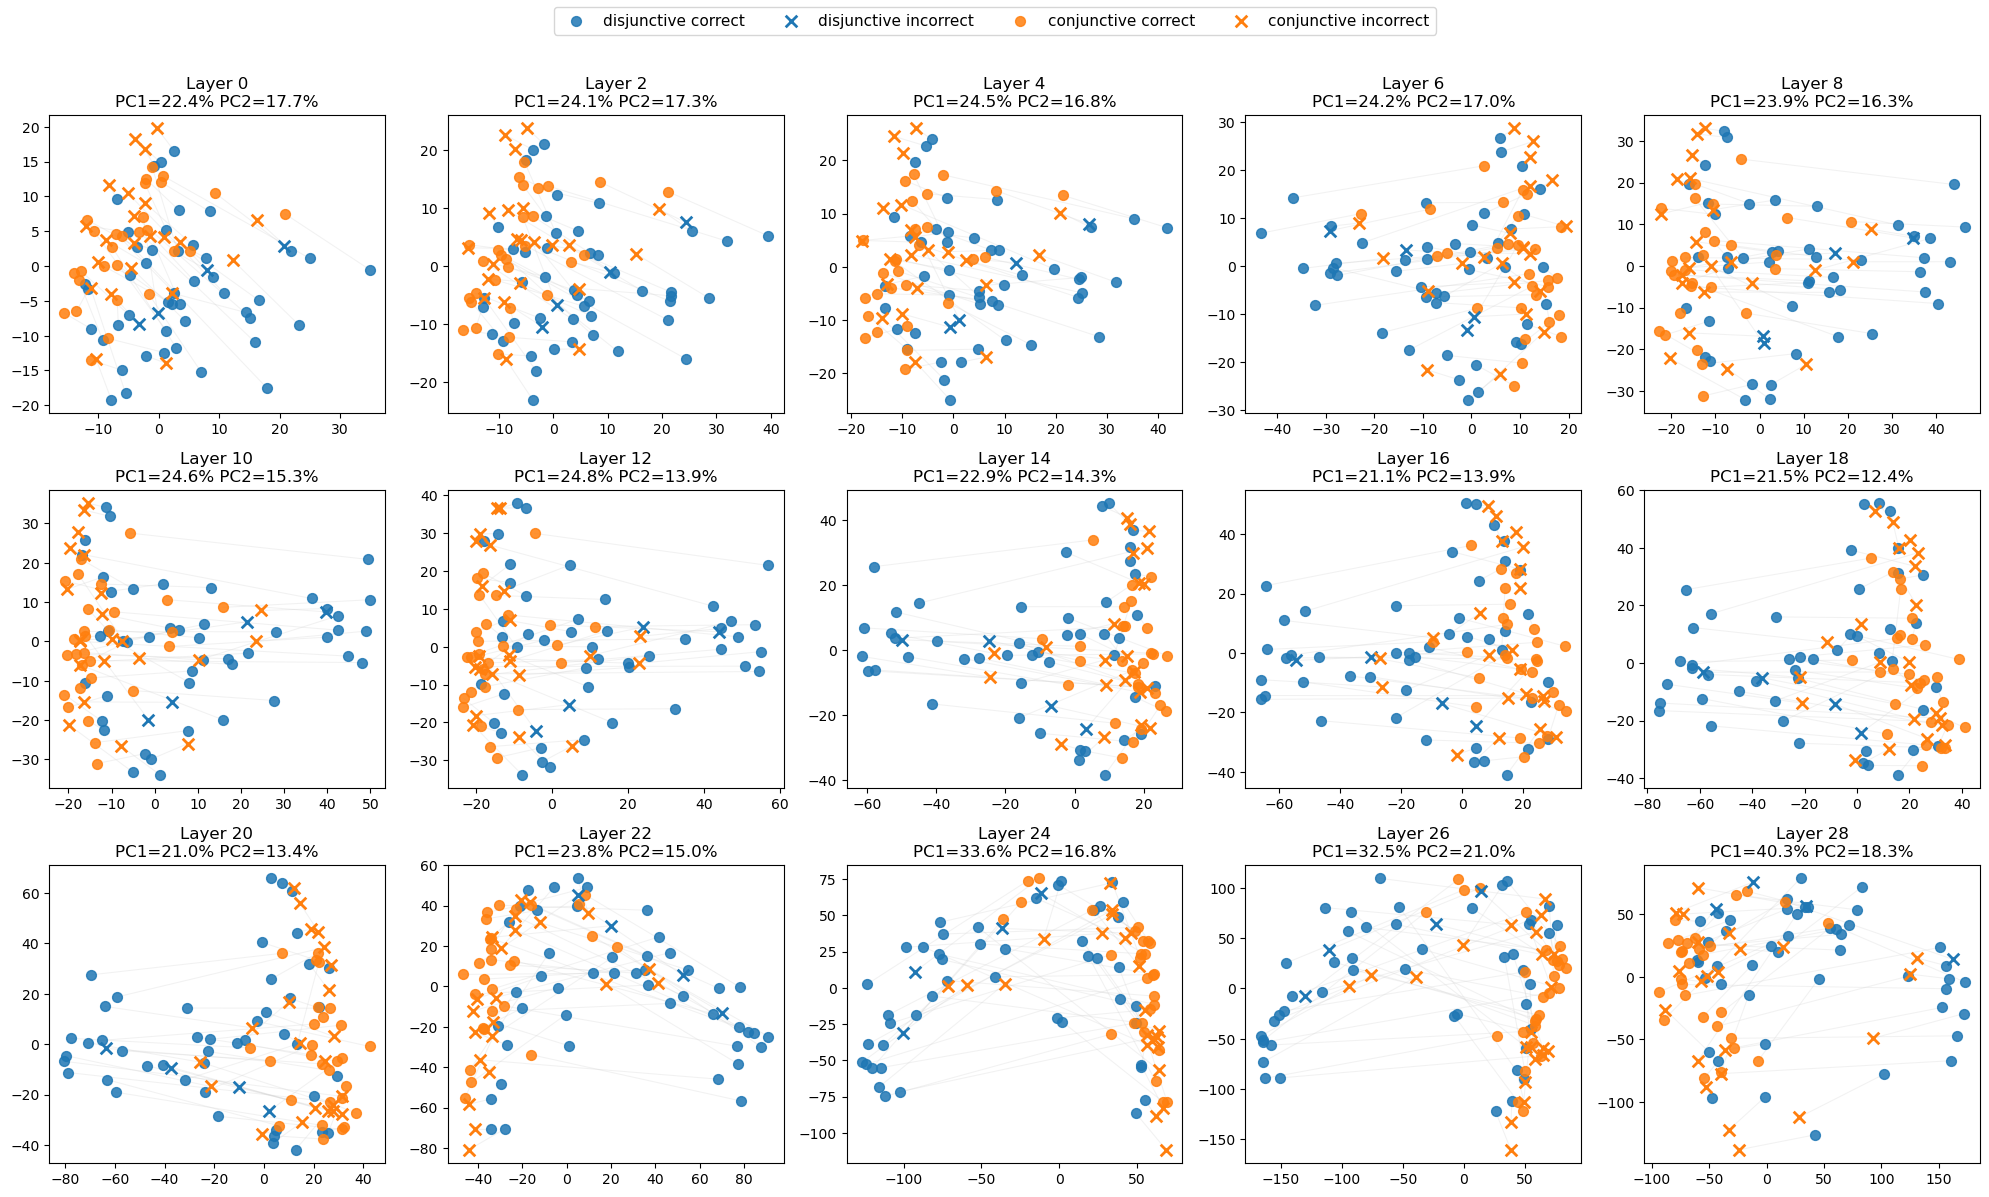

In [4]:



results_df = pd.read_csv(
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/qwen_search_results_counterfactual.csv"
)

# --------------------------------------------------
# FILTER TO 15 DISTRACTORS
# --------------------------------------------------

ND = 20

mask = (
    data["num_distractors"].numpy()
    == ND
)

conditions = np.array(
    data["conditions"]
)[mask]

trials = (
    data["trials"]
    .numpy()[mask]
)

lookup = results_df.set_index(
    [
        "condition",
        "num_distractors",
        "trial",
    ]
)["correct"].to_dict()

correct = np.array([
    lookup[
        (
            c,
            ND,
            int(t),
        )
    ]
    for c, t in zip(
        conditions,
        trials,
    )
])


n_layers = data[
    "bbox_mean_hidden"
].shape[1]

layers = list(
    range(
        0,
        n_layers,
        2,
    )
)

fig, axes = plt.subplots(
    3,
    5,
    figsize=(20, 12),
)

axes = axes.flatten()



for ax, layer in zip(
    axes,
    layers,
):

    X = (
        data[
            "center_token_hidden"
        ][mask, layer]
        .float()
        .numpy()
    )

    pca = PCA(
        n_components=2
    )

    X_pca = pca.fit_transform(X)

    df = pd.DataFrame({
        "pc1": X_pca[:, 0],
        "pc2": X_pca[:, 1],
        "condition": conditions,
        "trial": trials,
        "correct": correct,
    })

    # ----------------------------------------------
    # paired lines
    # ----------------------------------------------

    pivot = (
        df.pivot(
            index="trial",
            columns="condition",
            values=["pc1", "pc2"],
        )
    )

    for trial in pivot.index:

        try:

            x1 = pivot.loc[
                trial,
                ("pc1", "disjunctive")
            ]
            y1 = pivot.loc[
                trial,
                ("pc2", "disjunctive")
            ]

            x2 = pivot.loc[
                trial,
                ("pc1", "conjunctive")
            ]
            y2 = pivot.loc[
                trial,
                ("pc2", "conjunctive")
            ]

            ax.plot(
                [x1, x2],
                [y1, y2],
                color="lightgray",
                alpha=0.3,
                linewidth=0.75,
                zorder=1,
            )

        except KeyError:
            pass

    # ----------------------------------------------
    # CORRECT = circles
    # INCORRECT = x
    # color by condition
    # ----------------------------------------------

    colors = {
        "disjunctive": "C0",
        "conjunctive": "C1",
    }

    for condition in [
        "disjunctive",
        "conjunctive",
    ]:

        sub = df[
            df["condition"]
            == condition
        ]

        # correct
        m = sub["correct"]

        ax.scatter(
            sub.loc[m, "pc1"],
            sub.loc[m, "pc2"],
            s=50,
            marker="o",
            color=colors[condition],
            alpha=0.85,
            label=f"{condition} correct"
            if layer == 0 else None,
            zorder=3,
        )

        # incorrect
        ax.scatter(
            sub.loc[~m, "pc1"],
            sub.loc[~m, "pc2"],
            s=70,
            marker="x",
            linewidth=2,
            color=colors[condition],
            alpha=1.0,
            label=f"{condition} incorrect"
            if layer == 0 else None,
            zorder=4,
        )

    ax.set_title(
        f"Layer {layer}\n"
        f"PC1={100*pca.explained_variance_ratio_[0]:.1f}% "
        f"PC2={100*pca.explained_variance_ratio_[1]:.1f}%"
    )

# --------------------------------------------------
# REMOVE UNUSED AXES
# --------------------------------------------------

for ax in axes[len(layers):]:
    ax.axis("off")

# --------------------------------------------------
# LEGEND
# --------------------------------------------------

handles, labels = (
    axes[0]
    .get_legend_handles_labels()
)

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=4,
    fontsize=11,
)

plt.tight_layout(
    rect=[0, 0, 1, 0.95]
)

plt.show()

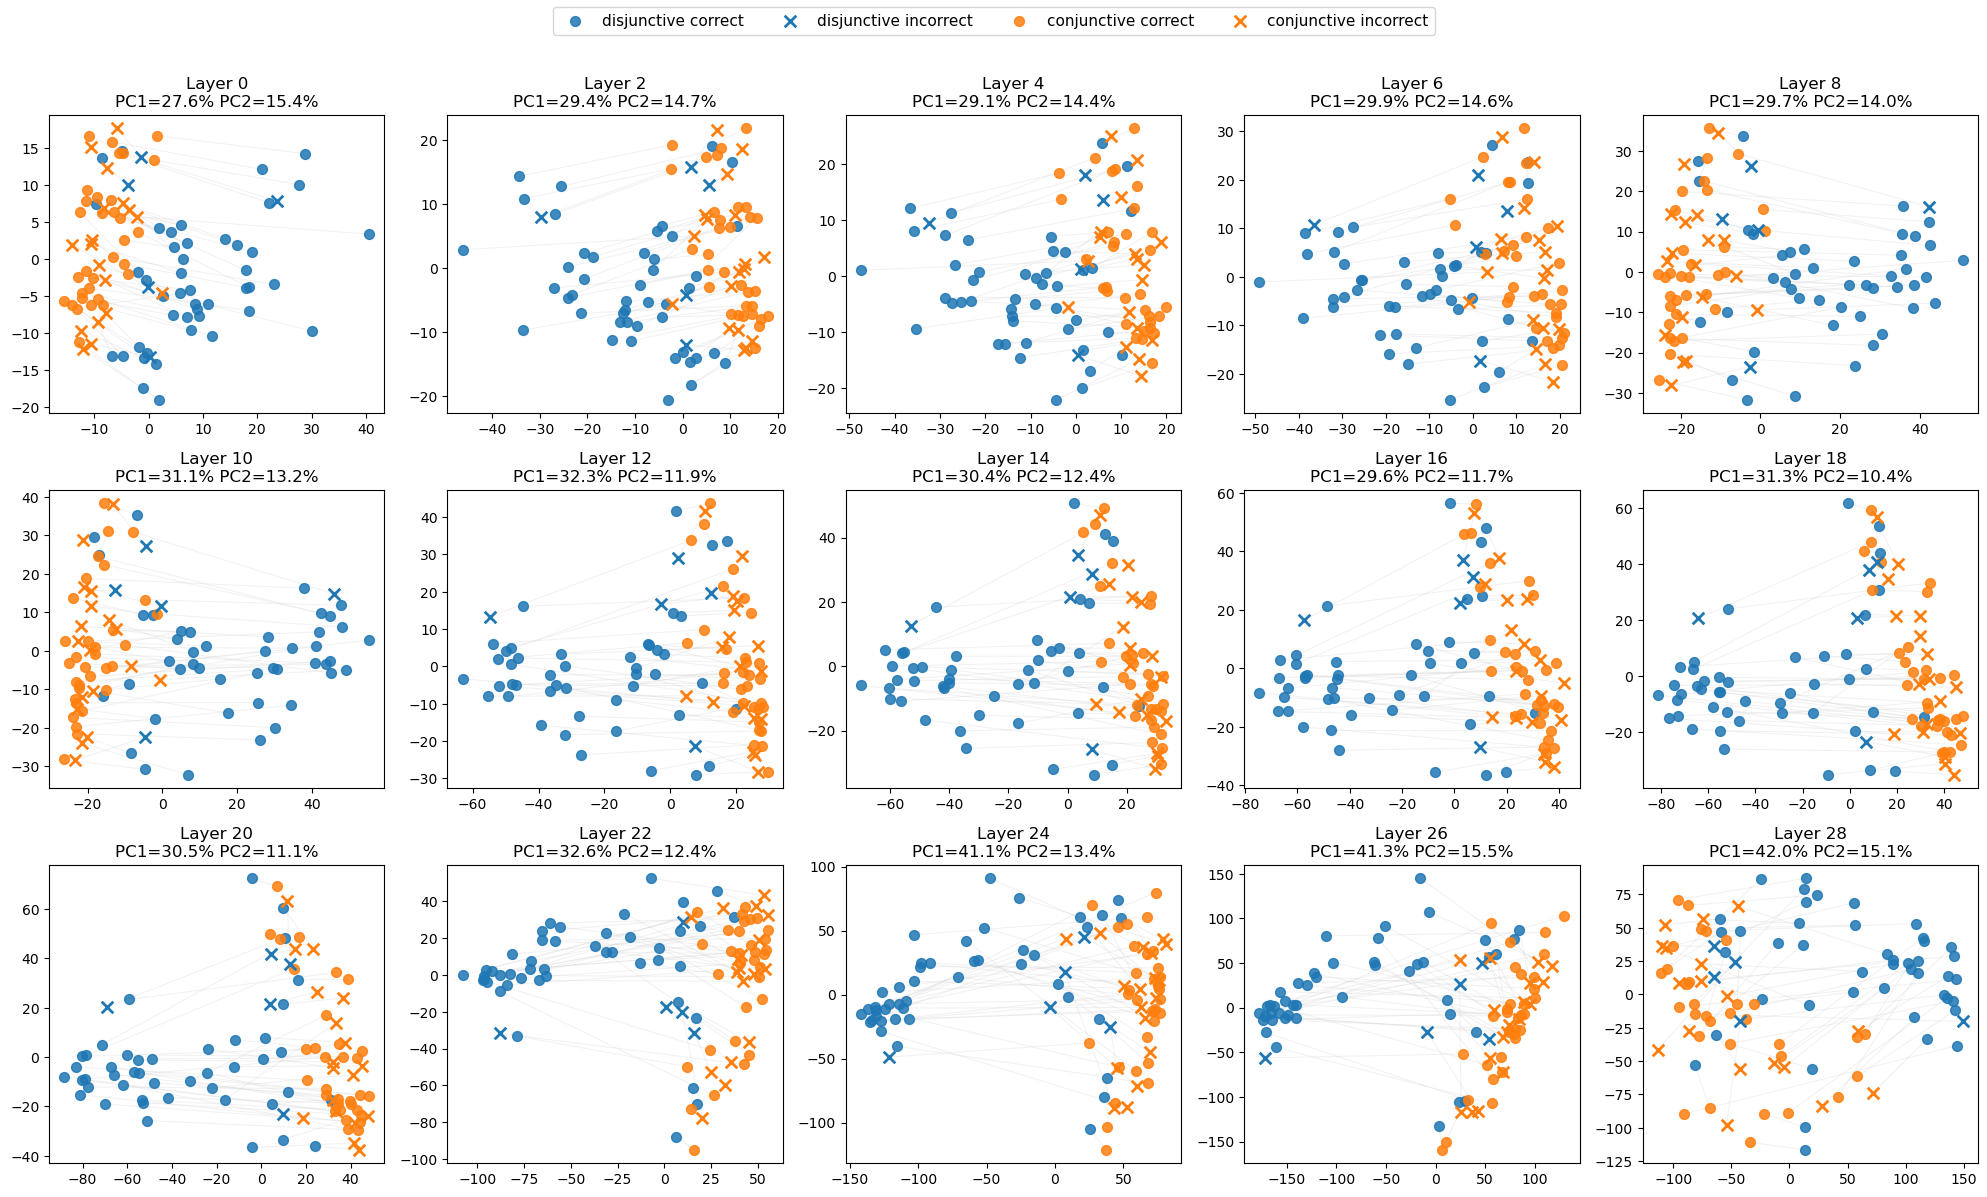

In [5]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import pandas as pd

# --------------------------------------------------
# LOAD BENCHMARK RESULTS
# --------------------------------------------------

results_df = pd.read_csv(
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/qwen_search_results_counterfactual.csv"
)

# --------------------------------------------------
# FILTER TO 15 DISTRACTORS
# --------------------------------------------------

ND = 40

mask = (
    data["num_distractors"].numpy()
    == ND
)

conditions = np.array(
    data["conditions"]
)[mask]

trials = (
    data["trials"]
    .numpy()[mask]
)

# --------------------------------------------------
# LOOKUP CORRECTNESS
# --------------------------------------------------

lookup = results_df.set_index(
    [
        "condition",
        "num_distractors",
        "trial",
    ]
)["correct"].to_dict()

correct = np.array([
    lookup[
        (
            c,
            ND,
            int(t),
        )
    ]
    for c, t in zip(
        conditions,
        trials,
    )
])

# --------------------------------------------------
# LAYERS
# --------------------------------------------------

n_layers = data[
    "center_token_hidden"
].shape[1]

layers = list(
    range(
        0,
        n_layers,
        2,
    )
)

fig, axes = plt.subplots(
    3,
    5,
    figsize=(20, 12),
)

axes = axes.flatten()

# --------------------------------------------------
# PCA PER LAYER
# --------------------------------------------------

for ax, layer in zip(
    axes,
    layers,
):

    X = (
        data[
            "center_token_hidden"
        ][mask, layer]
        .float()
        .numpy()
    )

    pca = PCA(
        n_components=2
    )

    X_pca = pca.fit_transform(X)

    df = pd.DataFrame({
        "pc1": X_pca[:, 0],
        "pc2": X_pca[:, 1],
        "condition": conditions,
        "trial": trials,
        "correct": correct,
    })

    # ----------------------------------------------
    # paired lines
    # ----------------------------------------------

    pivot = (
        df.pivot(
            index="trial",
            columns="condition",
            values=["pc1", "pc2"],
        )
    )

    for trial in pivot.index:

        try:

            x1 = pivot.loc[
                trial,
                ("pc1", "disjunctive")
            ]
            y1 = pivot.loc[
                trial,
                ("pc2", "disjunctive")
            ]

            x2 = pivot.loc[
                trial,
                ("pc1", "conjunctive")
            ]
            y2 = pivot.loc[
                trial,
                ("pc2", "conjunctive")
            ]

            ax.plot(
                [x1, x2],
                [y1, y2],
                color="lightgray",
                alpha=0.3,
                linewidth=0.75,
                zorder=1,
            )

        except KeyError:
            pass

    # ----------------------------------------------
    # CORRECT = circles
    # INCORRECT = x
    # color by condition
    # ----------------------------------------------

    colors = {
        "disjunctive": "C0",
        "conjunctive": "C1",
    }

    for condition in [
        "disjunctive",
        "conjunctive",
    ]:

        sub = df[
            df["condition"]
            == condition
        ]

        # correct
        m = sub["correct"]

        ax.scatter(
            sub.loc[m, "pc1"],
            sub.loc[m, "pc2"],
            s=50,
            marker="o",
            color=colors[condition],
            alpha=0.85,
            label=f"{condition} correct"
            if layer == 0 else None,
            zorder=3,
        )

        # incorrect
        ax.scatter(
            sub.loc[~m, "pc1"],
            sub.loc[~m, "pc2"],
            s=70,
            marker="x",
            linewidth=2,
            color=colors[condition],
            alpha=1.0,
            label=f"{condition} incorrect"
            if layer == 0 else None,
            zorder=4,
        )

    ax.set_title(
        f"Layer {layer}\n"
        f"PC1={100*pca.explained_variance_ratio_[0]:.1f}% "
        f"PC2={100*pca.explained_variance_ratio_[1]:.1f}%"
    )

# --------------------------------------------------
# REMOVE UNUSED AXES
# --------------------------------------------------

for ax in axes[len(layers):]:
    ax.axis("off")

# --------------------------------------------------
# LEGEND
# --------------------------------------------------

handles, labels = (
    axes[0]
    .get_legend_handles_labels()
)

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=4,
    fontsize=11,
)

plt.tight_layout(
    rect=[0, 0, 1, 0.95]
)

plt.show()

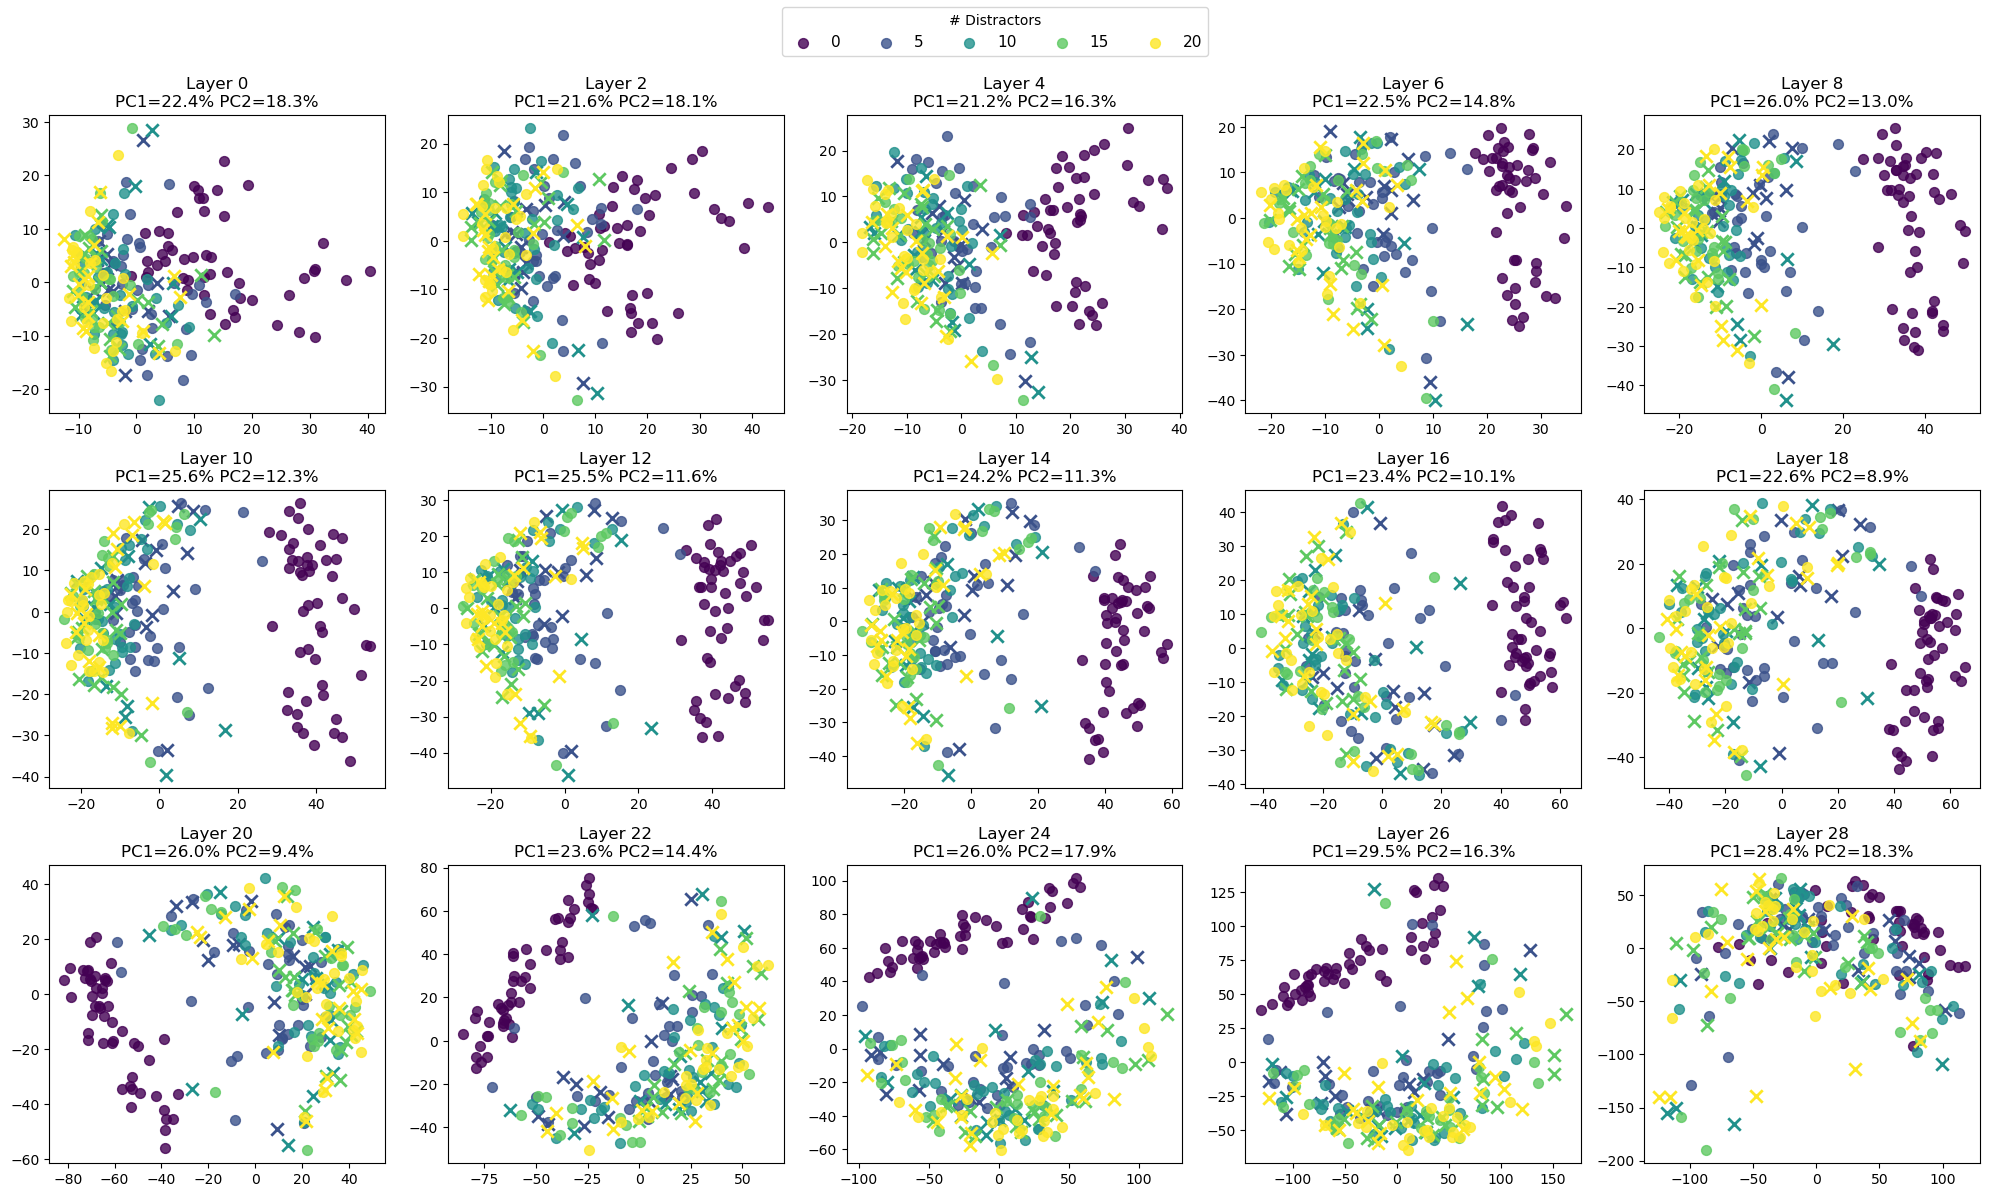

In [6]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import pandas as pd

# ==================================================
# LOAD BENCHMARK RESULTS
# ==================================================

results_df = pd.read_csv(
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/qwen_search_results_counterfactual.csv"
)

# ==================================================
# FILTER TO CONJUNCTIVE
# ==================================================

condition_mask = (
    np.array(data["conditions"])
    == "conjunctive"
)

mask_idx = np.where(
    condition_mask
)[0]

trials = (
    data["trials"]
    .numpy()[condition_mask]
)

num_distractors = (
    data["num_distractors"]
    .numpy()[condition_mask]
)

# only keep <=20 distractors

keep = (
    (num_distractors <= 20)
    #& (num_distractors > 0)
)

mask_idx = mask_idx[keep]
trials = trials[keep]
num_distractors = num_distractors[keep]

# ==================================================
# LOOKUP CORRECTNESS
# ==================================================

lookup = (
    results_df
    .set_index(
        [
            "condition",
            "num_distractors",
            "trial",
        ]
    )["correct"]
    .to_dict()
)

correct = np.array([
    lookup.get(
        (
            "conjunctive",
            int(nd),
            int(t),
        ),
        np.nan,
    )
    for nd, t in zip(
        num_distractors,
        trials,
    )
])

# ==================================================
# COLORS
# ==================================================

unique_nd = np.sort(
    np.unique(
        num_distractors
    )
)

cmap = plt.cm.viridis

color_dict = {
    nd: cmap(
        i / (len(unique_nd) - 1)
    )
    for i, nd in enumerate(
        unique_nd
    )
}

# ==================================================
# LAYERS
# ==================================================

n_layers = data[
    "center_token_hidden"
].shape[1]

layers = list(
    range(
        0,
        n_layers,
        2,
    )
)

fig, axes = plt.subplots(
    3,
    5,
    figsize=(20, 12),
)

axes = axes.flatten()

# ==================================================
# PCA PER LAYER
# ==================================================

for ax, layer in zip(
    axes,
    layers,
):

    X = (
        data[
            "center_token_hidden"
        ][mask_idx, layer]
        .float()
        .numpy()
    )

    pca = PCA(
        n_components=2
    )

    X_pca = pca.fit_transform(X)

    df = pd.DataFrame({
        "pc1": X_pca[:, 0],
        "pc2": X_pca[:, 1],
        "trial": trials,
        "correct": correct,
        "num_distractors":
            num_distractors,
    })

    # ----------------------------------------------
    # plot by distractor count
    # ----------------------------------------------

    for nd in unique_nd:

        sub = df[
            df["num_distractors"]
            == nd
        ]

        c = color_dict[nd]

        # ------------------------
        # correct = circles
        # ------------------------

        m = (
            sub["correct"]
            == True
        )

        ax.scatter(
            sub.loc[m, "pc1"],
            sub.loc[m, "pc2"],
            color=c,
            marker="o",
            s=50,
            alpha=0.8,
            label=f"{nd}"
            if layer == 0 else None,
        )

        # ------------------------
        # incorrect = X
        # ------------------------

        bad = (
            sub["correct"]
            == False
        )

        ax.scatter(
            sub.loc[bad, "pc1"],
            sub.loc[bad, "pc2"],
            color=c,
            marker="x",
            s=80,
            linewidth=2,
            alpha=1.0,
        )

    ax.set_title(
        f"Layer {layer}\n"
        f"PC1={100*pca.explained_variance_ratio_[0]:.1f}% "
        f"PC2={100*pca.explained_variance_ratio_[1]:.1f}%"
    )

# ==================================================
# REMOVE UNUSED AXES
# ==================================================

for ax in axes[len(layers):]:
    ax.axis("off")

# ==================================================
# LEGEND
# ==================================================

handles, labels = (
    axes[0]
    .get_legend_handles_labels()
)

fig.legend(
    handles,
    labels,
    title="# Distractors",
    loc="upper center",
    ncol=len(unique_nd),
    fontsize=11,
)

plt.tight_layout(
    rect=[0, 0, 1, 0.95]
)

plt.show()

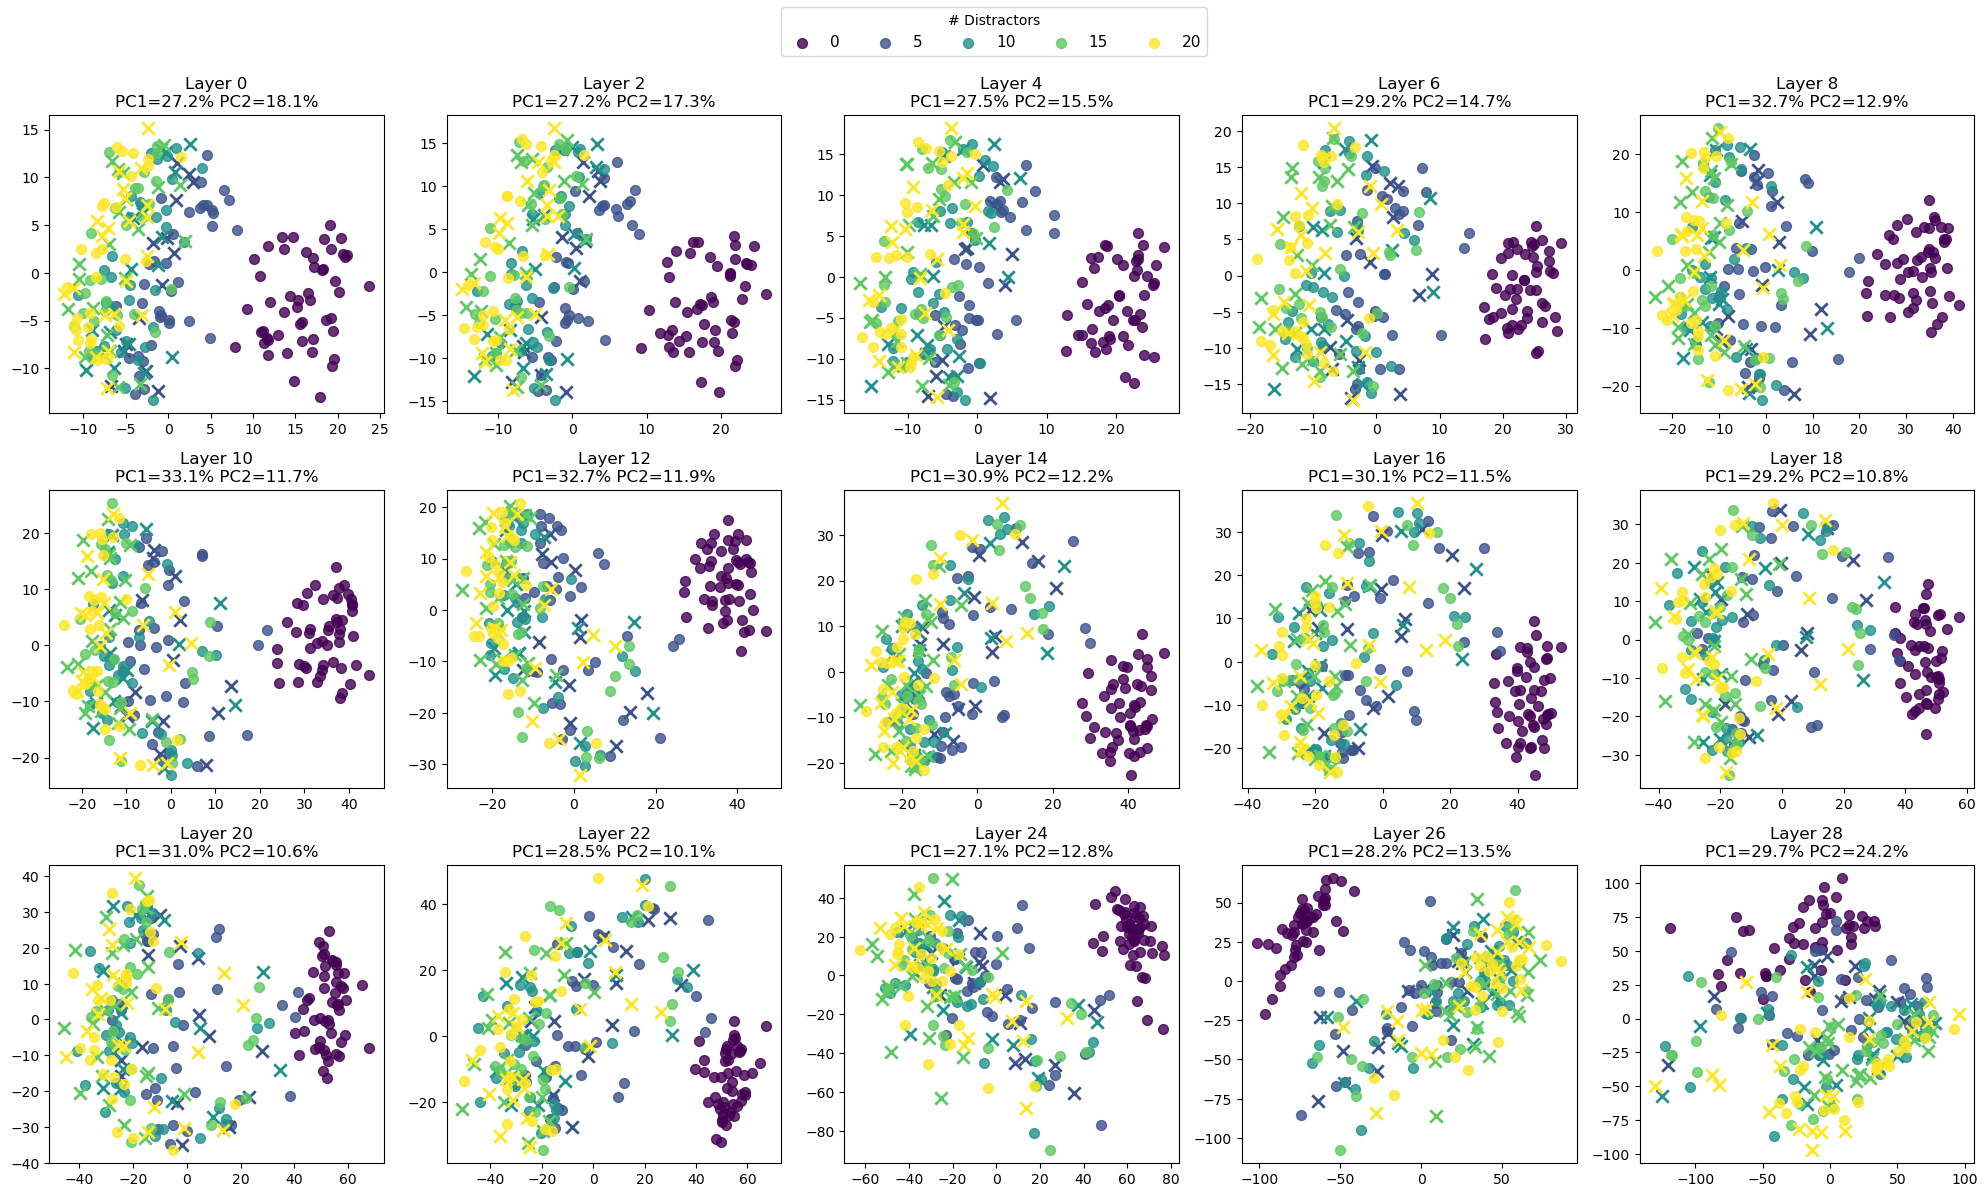

In [7]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import pandas as pd

# ==================================================
# LOAD BENCHMARK RESULTS
# ==================================================

results_df = pd.read_csv(
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/qwen_search_results_counterfactual.csv"
)

# ==================================================
# FILTER TO CONJUNCTIVE
# ==================================================

condition_mask = (
    np.array(data["conditions"])
    == "conjunctive"
)

mask_idx = np.where(
    condition_mask
)[0]

trials = (
    data["trials"]
    .numpy()[condition_mask]
)

num_distractors = (
    data["num_distractors"]
    .numpy()[condition_mask]
)

# only keep <=20 distractors

keep = (
    (num_distractors <= 20)
    #& (num_distractors > 0)
)

mask_idx = mask_idx[keep]
trials = trials[keep]
num_distractors = num_distractors[keep]

# ==================================================
# LOOKUP CORRECTNESS
# ==================================================

lookup = (
    results_df
    .set_index(
        [
            "condition",
            "num_distractors",
            "trial",
        ]
    )["correct"]
    .to_dict()
)

correct = np.array([
    lookup.get(
        (
            "conjunctive",
            int(nd),
            int(t),
        ),
        np.nan,
    )
    for nd, t in zip(
        num_distractors,
        trials,
    )
])

# ==================================================
# COLORS
# ==================================================

unique_nd = np.sort(
    np.unique(
        num_distractors
    )
)

cmap = plt.cm.viridis

color_dict = {
    nd: cmap(
        i / (len(unique_nd) - 1)
    )
    for i, nd in enumerate(
        unique_nd
    )
}

# ==================================================
# LAYERS
# ==================================================

n_layers = data[
    "center_token_hidden"
].shape[1]

layers = list(
    range(
        0,
        n_layers,
        2,
    )
)

fig, axes = plt.subplots(
    3,
    5,
    figsize=(20, 12),
)

axes = axes.flatten()

# ==================================================
# PCA PER LAYER
# ==================================================

for ax, layer in zip(
    axes,
    layers,
):

    X = (
        data[
            "bbox_mean_hidden"
        ][mask_idx, layer]
        .float()
        .numpy()
    )

    pca = PCA(
        n_components=2
    )

    X_pca = pca.fit_transform(X)

    df = pd.DataFrame({
        "pc1": X_pca[:, 0],
        "pc2": X_pca[:, 1],
        "trial": trials,
        "correct": correct,
        "num_distractors":
            num_distractors,
    })

    # ----------------------------------------------
    # plot by distractor count
    # ----------------------------------------------

    for nd in unique_nd:

        sub = df[
            df["num_distractors"]
            == nd
        ]

        c = color_dict[nd]

        # ------------------------
        # correct = circles
        # ------------------------

        m = (
            sub["correct"]
            == True
        )

        ax.scatter(
            sub.loc[m, "pc1"],
            sub.loc[m, "pc2"],
            color=c,
            marker="o",
            s=50,
            alpha=0.8,
            label=f"{nd}"
            if layer == 0 else None,
        )

        # ------------------------
        # incorrect = X
        # ------------------------

        bad = (
            sub["correct"]
            == False
        )

        ax.scatter(
            sub.loc[bad, "pc1"],
            sub.loc[bad, "pc2"],
            color=c,
            marker="x",
            s=80,
            linewidth=2,
            alpha=1.0,
        )

    ax.set_title(
        f"Layer {layer}\n"
        f"PC1={100*pca.explained_variance_ratio_[0]:.1f}% "
        f"PC2={100*pca.explained_variance_ratio_[1]:.1f}%"
    )

# ==================================================
# REMOVE UNUSED AXES
# ==================================================

for ax in axes[len(layers):]:
    ax.axis("off")

# ==================================================
# LEGEND
# ==================================================

handles, labels = (
    axes[0]
    .get_legend_handles_labels()
)

fig.legend(
    handles,
    labels,
    title="# Distractors",
    loc="upper center",
    ncol=len(unique_nd),
    fontsize=11,
)

plt.tight_layout(
    rect=[0, 0, 1, 0.95]
)

plt.show()

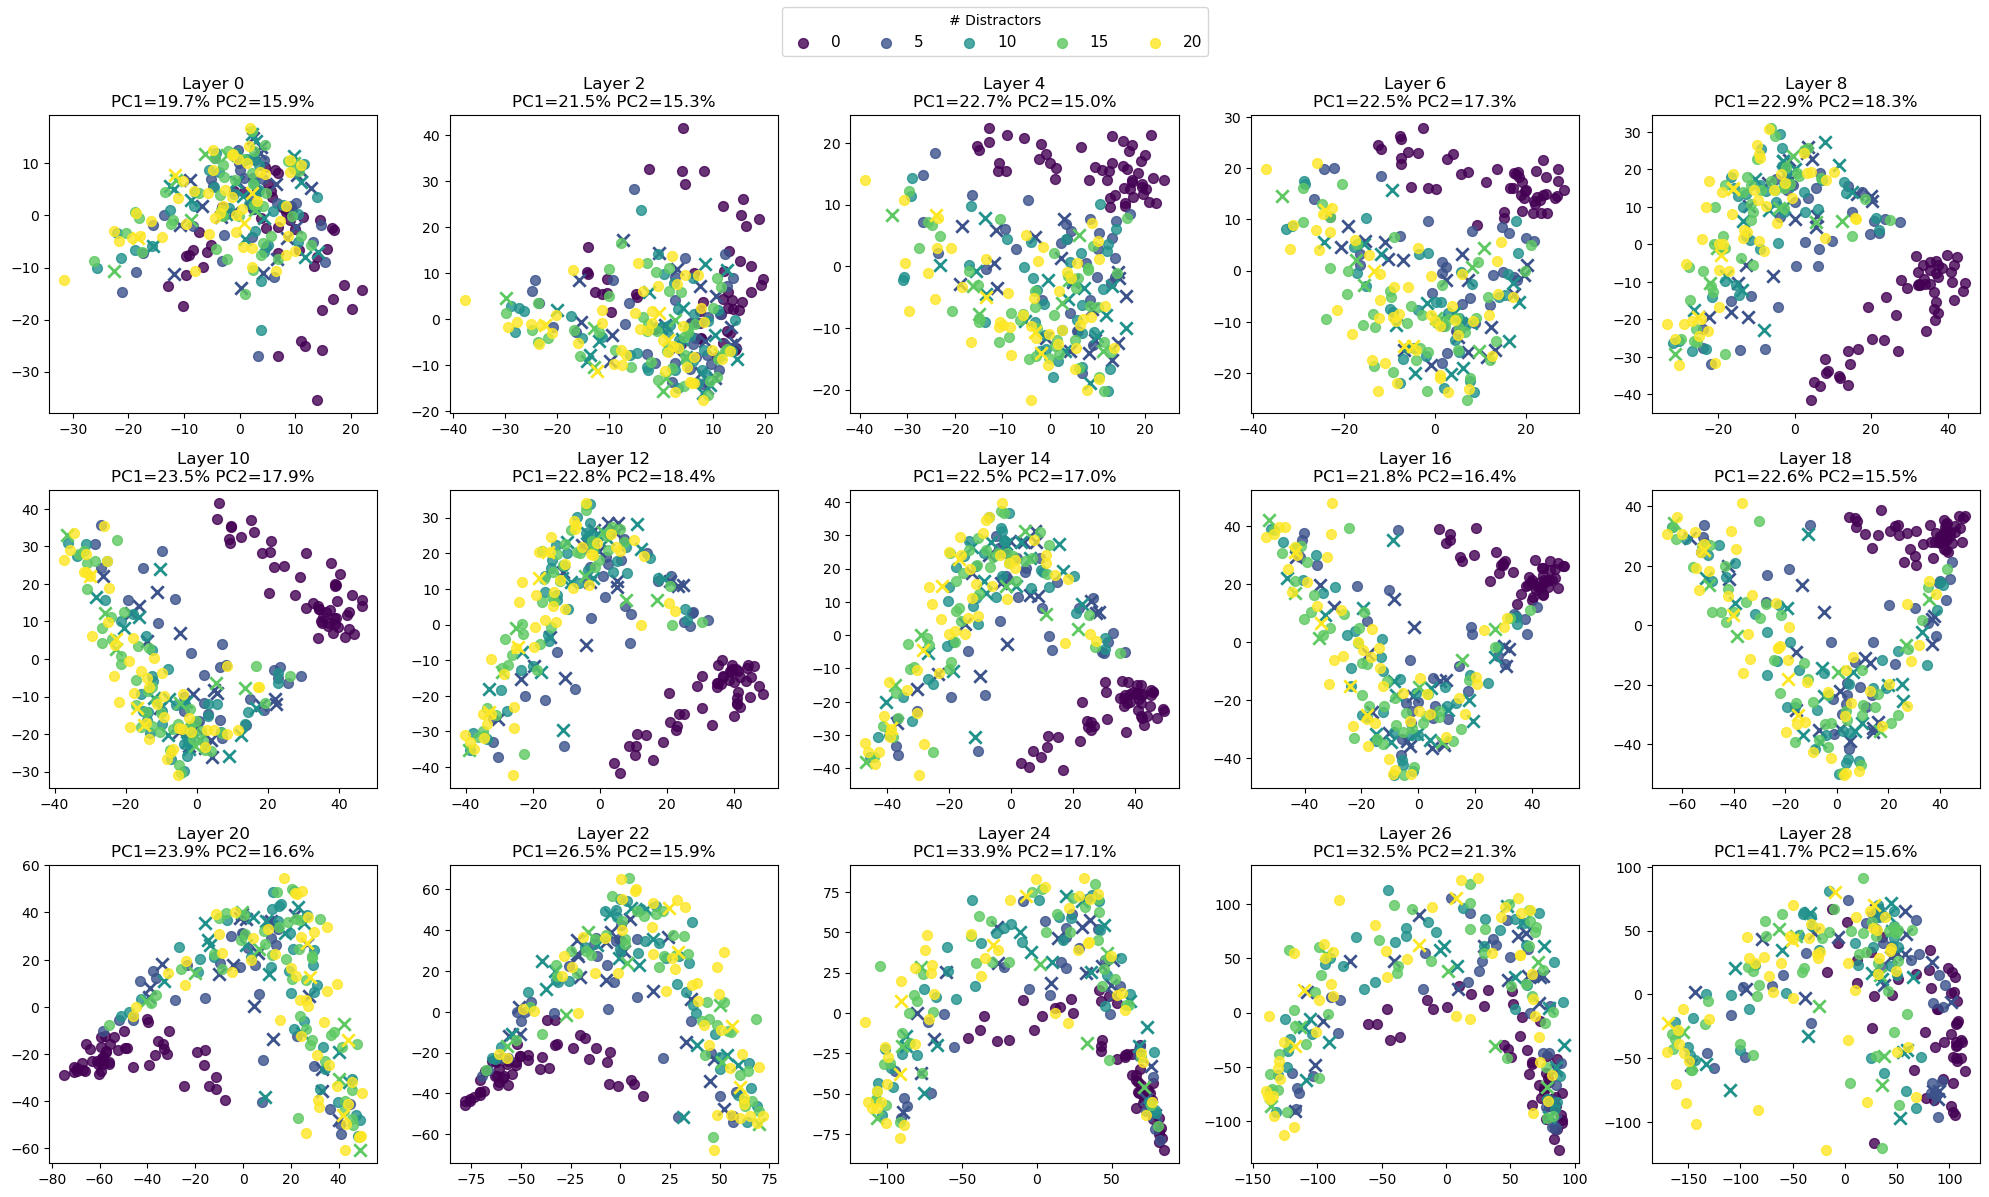

In [8]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import pandas as pd

# ==================================================
# LOAD BENCHMARK RESULTS
# ==================================================

results_df = pd.read_csv(
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/qwen_search_results_counterfactual.csv"
)

# ==================================================
# FILTER TO DISJUNCTIVE
# ==================================================

condition_mask = (
    np.array(data["conditions"])
    == "disjunctive"
)

mask_idx = np.where(
    condition_mask
)[0]

trials = (
    data["trials"]
    .numpy()[condition_mask]
)

num_distractors = (
    data["num_distractors"]
    .numpy()[condition_mask]
)

# only keep <=20 distractors

keep = (
    (num_distractors <= 20)
    #& (num_distractors > 0)
)

mask_idx = mask_idx[keep]
trials = trials[keep]
num_distractors = num_distractors[keep]

# ==================================================
# LOOKUP CORRECTNESS
# ==================================================

lookup = (
    results_df
    .set_index(
        [
            "condition",
            "num_distractors",
            "trial",
        ]
    )["correct"]
    .to_dict()
)

correct = np.array([
    lookup.get(
        (
            "disjunctive",
            int(nd),
            int(t),
        ),
        np.nan,
    )
    for nd, t in zip(
        num_distractors,
        trials,
    )
])

# ==================================================
# COLORS
# ==================================================

unique_nd = np.sort(
    np.unique(
        num_distractors
    )
)

cmap = plt.cm.viridis

color_dict = {
    nd: cmap(
        i / (len(unique_nd) - 1)
    )
    for i, nd in enumerate(
        unique_nd
    )
}

# ==================================================
# LAYERS
# ==================================================

n_layers = data[
    "center_token_hidden"
].shape[1]

layers = list(
    range(
        0,
        n_layers,
        2,
    )
)

fig, axes = plt.subplots(
    3,
    5,
    figsize=(20, 12),
)

axes = axes.flatten()

# ==================================================
# PCA PER LAYER
# ==================================================

for ax, layer in zip(
    axes,
    layers,
):

    X = (
        data[
            "center_token_hidden"
        ][mask_idx, layer]
        .float()
        .numpy()
    )

    pca = PCA(
        n_components=2
    )

    X_pca = pca.fit_transform(X)

    df = pd.DataFrame({
        "pc1": X_pca[:, 0],
        "pc2": X_pca[:, 1],
        "trial": trials,
        "correct": correct,
        "num_distractors":
            num_distractors,
    })

    # ----------------------------------------------
    # plot by distractor count
    # ----------------------------------------------

    for nd in unique_nd:

        sub = df[
            df["num_distractors"]
            == nd
        ]

        c = color_dict[nd]

        # ------------------------
        # correct = circles
        # ------------------------

        m = (
            sub["correct"]
            == True
        )

        ax.scatter(
            sub.loc[m, "pc1"],
            sub.loc[m, "pc2"],
            color=c,
            marker="o",
            s=50,
            alpha=0.8,
            label=f"{nd}"
            if layer == 0 else None,
        )

        # ------------------------
        # incorrect = X
        # ------------------------

        bad = (
            sub["correct"]
            == False
        )

        ax.scatter(
            sub.loc[bad, "pc1"],
            sub.loc[bad, "pc2"],
            color=c,
            marker="x",
            s=80,
            linewidth=2,
            alpha=1.0,
        )

    ax.set_title(
        f"Layer {layer}\n"
        f"PC1={100*pca.explained_variance_ratio_[0]:.1f}% "
        f"PC2={100*pca.explained_variance_ratio_[1]:.1f}%"
    )

# ==================================================
# REMOVE UNUSED AXES
# ==================================================

for ax in axes[len(layers):]:
    ax.axis("off")

# ==================================================
# LEGEND
# ==================================================

handles, labels = (
    axes[0]
    .get_legend_handles_labels()
)

fig.legend(
    handles,
    labels,
    title="# Distractors",
    loc="upper center",
    ncol=len(unique_nd),
    fontsize=11,
)

plt.tight_layout(
    rect=[0, 0, 1, 0.95]
)

plt.show()